## Atlas

In [9]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

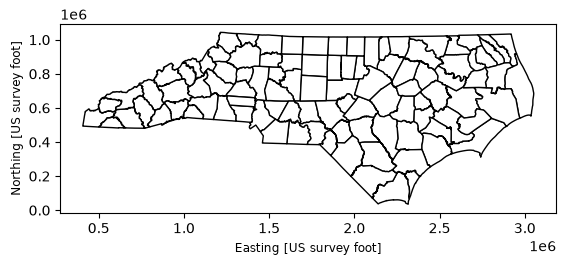

In [10]:
# Load NC county boundaries
nc_counties = gpd.read_file("data/countiesNC.geojson")

# Project to NC coordinate system
nc_counties = nc_counties.to_crs(6543)

# Plot counties
nc_counties.plot(edgecolor="black", facecolor="white")
plt.show()

In [11]:
# Load polling places
polling_places = gpd.read_file(
    "data/pollingnc.geojson"
)

# Match coordinate systems
polling_places = polling_places.to_crs(nc_counties.crs)

polling_places.head()

,FID,Status,Score,Match_type,Match_addr,Addr_type,Place_addr,Side,StPreDir,StPreType,...,USER_polli,USER_pol_1,USER_preci,USER_house,USER_stree,USER_addre,USER_city,USER_state,USER_zip,geometry
0,1,T,99.55,A,"621 E Haggard Ave, Elon, North Carolina, 27244",StreetAddress,"621 E Haggard Ave, Elon, North Carolina, 27244",R,E,,...,12,FIRST BAPTIST CHURCH OF ELON,NORTH BOONE,621,HAGGARD AVE,621 HAGGARD AVE,ELON,NC,27244,POINT (1853259.616 857054.995)
1,2,M,100.00,A,"810 Wicker St, Burlington, North Carolina, 27217",StreetAddress,"810 Wicker St, Burlington, North Carolina, 27217",L,,,...,10,ELMIRA COMMUNITY CENTER,BURLINGTON 7,810,WICKER ST,810 WICKER ST,BURLINGTON,NC,27217,POINT (1869425.883 858154.04)
2,3,M,100.00,A,"101 Boone Rd, Burlington, North Carolina, 27217",PointAddress,"101 Boone Rd, Burlington, North Carolina, 27217",,,,...,13,LAKEVIEW COMMUNITY CHURCH,FAUCETTE,101,BOONE RD,101 BOONE RD,BURLINGTON,NC,27217,POINT (1875088.197 875880.048)
3,4,M,100.00,A,"2744 Maple Ave, Burlington, North Carolina, 27215",StreetAddress,"2744 Maple Ave, Burlington, North Carolina, 27215",R,,,...,14,FELLOWSHIP BAPTIST CHURCH,GRAHAM 4,2744,MAPLE AVE,2744 MAPLE AVE,BURLINGTON,NC,27215,POINT (1871745.088 840379.025)
4,5,M,85.00,A,"27215, Burlington, North Carolina",Postal,"Burlington, North Carolina, 27215",,,,...,1,ALAMANCE CIVITAN CLUB HOUSE,COBLE,3328,DOCTOR PICKETT RD,3328 DOCTOR PICKETT RD,BURLINGTON,NC,27215,POINT (1869971.902 851187.31)


In [12]:
# Spatial join polling places to counties
polling_joined = gpd.sjoin(
    polling_places,
    nc_counties[["NAME", "geometry"]],
    how="inner",
    predicate="within"
)

# Count polling places in each county
polling_counts = polling_joined.groupby("NAME").size()

# View results
polling_counts.head()

NAME
Alamance     38
Alexander    10
Alleghany     4
Anson         8
Ashe         17
dtype: int64

In [ ]:
def county_map(county, ax):

    # Select county
    selected = nc_counties[
        nc_counties["NAME"] == county
    ]

    # Select polling places in county
    selected_polling = polling_joined[
        polling_joined["NAME"] == county
    ]

    # Plot county
    selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#7b9b90"
    )

    # Plot polling places
    if not selected_polling.empty:
        selected_polling.plot(
            ax=ax,
            color="darkblue",
            markersize=12,
            alpha=0.8
        )

    ax.set_title("Polling Place Locations", fontsize=14)
    ax.set_axis_off()


In [ ]:
#locator map function
def locator_map(county, ax):

    # Select county
    selected = nc_counties[
        nc_counties["NAME"] == county
    ]

    # Plot NC counties
    nc_counties.plot(
        ax=ax,
        edgecolor="gray",
        facecolor="white",
        linewidth=0.5
    )

    # Highlight selected county
    selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#7b9b90"
    )

    ax.set_title("Location in North Carolina", fontsize=10)
    ax.set_axis_off()

In [ ]:
#info per polling place function- how many per county
def county_info(county, ax):

    # Get polling place count
    count = polling_counts.get(county, 0)

    # Create sentence (string concatenation)
    sentence = (
        "There are " + str(count) +
        " polling places in " + county + " County."
    )

    # Add heading
    ax.text(
        0.05, 0.75,
        "POLLING PLACES",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        color="darkblue"
    )

    # Add spatial join result
    ax.text(
        0.05, 0.50,
        sentence,
        transform=ax.transAxes,
        fontsize=14,
        color="black",
        wrap=True,
        va="top"
    )

    ax.set_axis_off()

In [ ]:
#create atlas pages
def county_figure(county, pdf):

    # Create figure
    fig = plt.figure(figsize=(12, 8))

    # Set positions for maps and text
    ax_county = fig.add_axes([0.05, 0.18, 0.60, 0.62])
    ax_locator = fig.add_axes([0.70, 0.48, 0.25, 0.25])
    ax_info = fig.add_axes([0.70, 0.15, 0.25, 0.25])

    # Add maps and information
    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)

    # Atlas heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / Polling Places Atlas",
        fontsize=11,
        color="olivedrab"
    )

    # County name
    fig.text(
        0.05, 0.87,
        county + " County",
        fontsize=28,
        fontweight="bold"
    )

    # Legend
    fig.text(
        0.05, 0.12,
        "Blue dots represent polling place locations",
        fontsize=11,
        color="darkblue"
    )

    # Source
    fig.text(
        0.05, 0.04,
        "Sources: NC County Boundaries | NC Voting Polling Places",
        fontsize=9,
        color="gray"
    )

    # Save figure to PDF
    pdf.savefig(fig, dpi=100)

    # Close figure
    plt.close(fig)

In [ ]:
#test with durham
with PdfPages("Durham_Test.pdf") as pdf:
    county_figure("Durham", pdf)

In [ ]:
#generate complete atlas
# Sort counties alphabetically
nc_counties = nc_counties.sort_values(
    "NAME"
).reset_index(drop=True)

# Generate PDF atlas
with PdfPages("NC_Polling_Places_Atlas.pdf") as pdf:

    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

In [ ]:
#check join
print("Total polling places:", len(polling_places))
print("Polling places matched:", len(polling_joined))
print("Counties:", len(nc_counties))
print("Counties with polling places:", len(polling_counts))

Total polling places: 2662
Polling places matched: 2662
Counties: 100
Counties with polling places: 100


In [23]:
# Identify polling places not matched to a county
unmatched = polling_places.loc[
    ~polling_places.index.isin(polling_joined.index)
]

print("Unmatched polling places:", len(unmatched))

Unmatched polling places: 0
